# Single-Stock Risk Report
Jefferson Li

Adjusted-close analysis of the requested window, limited to actual supplied observations.

In [1]:
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

## Load cleaned data

In [2]:
from pathlib import Path
from datetime import date
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import scrapbook as sb

start = date.fromisoformat(start_date)
end = date.fromisoformat(end_date)
if start > end:
    raise ValueError("start_date must not follow end_date.")
ticker = str(ticker).strip().upper()
database = Path(db_path).expanduser()
if not database.is_file():
    raise FileNotFoundError(f"Database not found: {db_path}")
conn = sqlite3.connect(database.resolve().as_uri() + "?mode=ro", uri=True)
try:
    stock = pd.read_sql_query(
        "SELECT * FROM ohlc_hw_cleaned WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts",
        conn, params=(ticker, start_date, end_date), parse_dates=["ts"],
    )
finally:
    conn.close()
if len(stock) < 2:
    raise ValueError(f"{ticker}: need at least two prices in the requested window; found {len(stock)}.")
if stock["ts"].duplicated().any() or not np.isfinite(stock["adj_close"]).all() or stock["adj_close"].le(0).any():
    raise ValueError("Report requires unique dates and finite positive adjusted prices.")
prices = stock.set_index("ts")["adj_close"]
print(f"{ticker} from {start_date} to {end_date}: {len(stock)} trading days")
print(f"Actual observations: {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d}")
print("Coverage is limited to supplied observations; missing or trailing dates are not extrapolated.")
if len(stock) < 21:
    print("Insufficient history for 20-return rolling volatility (at least 21 prices needed).")
if len(stock) < 50:
    print("Insufficient history for the 50-price moving average.")
print("Retained raw-return review flags:", int(stock["outlier_review"].sum()))
display(stock[["ts", "ticker", "adj_close", "volume"]].head())
display(stock[["ts", "ticker", "adj_close", "volume"]].tail())


AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual observations: 2024-01-02 to 2024-10-18
Coverage is limited to supplied observations; missing or trailing dates are not extrapolated.
Retained raw-return review flags: 0


,ts,ticker,adj_close,volume
0,2024-01-02,AAPL,184.94,82488674
1,2024-01-03,AAPL,183.55,58414460
2,2024-01-04,AAPL,181.22,71983570
3,2024-01-05,AAPL,180.50,62379661
4,2024-01-08,AAPL,184.86,59144470


,ts,ticker,adj_close,volume
197,2024-10-14,AAPL,231.30,39882100
198,2024-10-15,AAPL,233.85,64751400
199,2024-10-16,AAPL,231.78,34082240
200,2024-10-17,AAPL,232.15,32993810
201,2024-10-18,AAPL,235.00,45441281


## Risk metrics
Daily returns are log returns. Volatility uses sample standard deviation and 252 trading days; Sharpe uses the course approximation with a 2% annual risk-free rate. Rolling estimates preserve warm-up gaps. Drawdown can recover; its minimum is maximum drawdown.

In [3]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Daily log returns, with no return at the first observation."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Annualized rolling sample volatility; preserve warm-up gaps."""
    return returns.rolling(window, min_periods=window).std(ddof=1) * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Per-date drawdown from the running peak; its minimum is maximum drawdown."""
    peak = prices.cummax()
    return (prices - peak) / peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Course annualized Sharpe approximation using daily log returns."""
    values = returns.dropna()
    volatility = values.std(ddof=1)
    if len(values) < 2 or not np.isfinite(volatility) or volatility <= 0:
        return np.nan
    return (values.mean() * 252 - risk_free_rate) / (volatility * np.sqrt(252))


returns = calculate_returns(prices)
rolling_volatility = calculate_volatility(returns)
moving_average = prices.rolling(50, min_periods=50).mean()
drawdown = calculate_max_drawdown(prices)
valid_returns = returns.dropna()
mean_rolling_volatility = rolling_volatility.mean()
summary_values = {
    "Total Return": prices.iloc[-1] / prices.iloc[0] - 1,
    "Annualized Return": np.expm1(valid_returns.sum() * 252 / len(valid_returns)),
    "Annualized Volatility": valid_returns.std(ddof=1) * np.sqrt(252),
    "Sharpe Ratio": calculate_sharpe_ratio(returns),
    "Maximum Drawdown": drawdown.min(),
    "Best Day": valid_returns.max(),
    "Worst Day": valid_returns.min(),
    "Positive Days": valid_returns.gt(0).mean(),
    "Average Up Day": valid_returns.loc[valid_returns.gt(0)].mean(),
    "Average Down Day": valid_returns.loc[valid_returns.lt(0)].mean(),
}


## Four-panel report

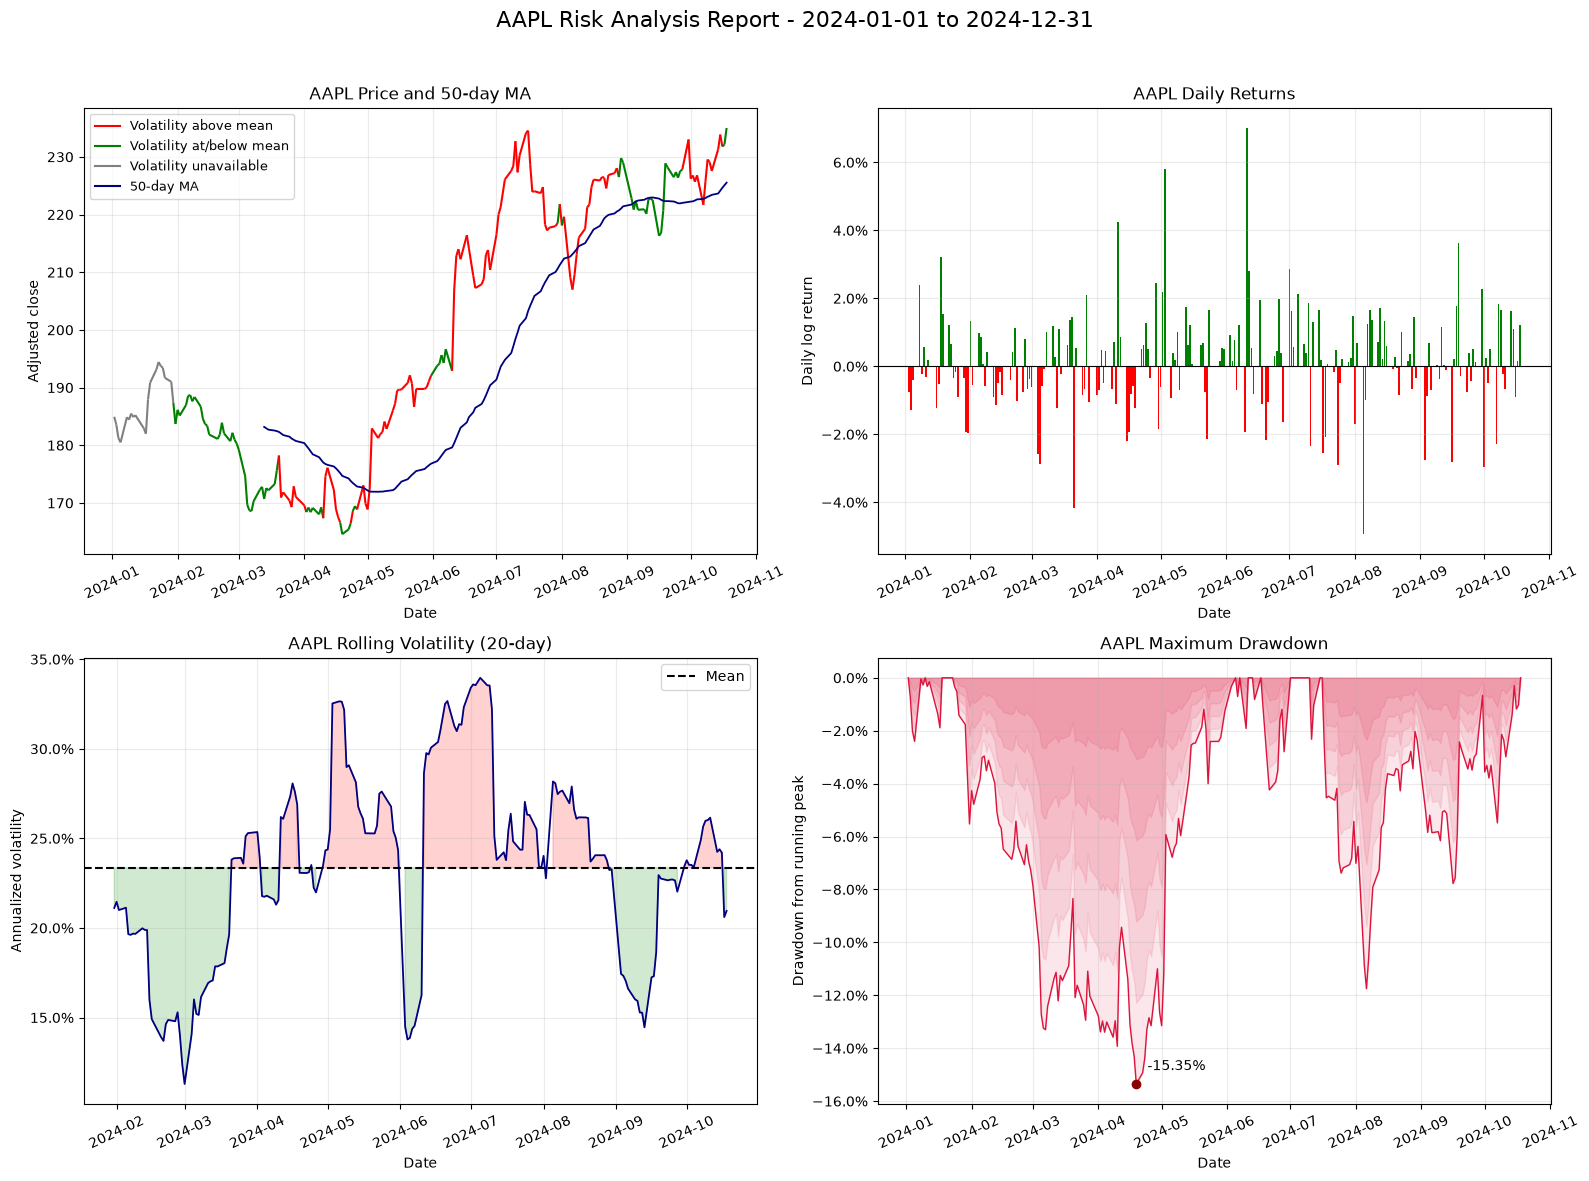

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
price_ax, returns_ax, volatility_ax, drawdown_ax = axes.ravel()
dates = prices.index.to_numpy()
x = mdates.date2num(dates)
y = prices.to_numpy(dtype=float)
vol = rolling_volatility.to_numpy(dtype=float)
points = np.column_stack([x, y])
segments = np.stack([points[:-1], points[1:]], axis=1)
colors = ["gray" if not np.isfinite(v) else "red" if v > mean_rolling_volatility else "green" for v in vol[1:]]
price_ax.add_collection(LineCollection(segments, colors=colors, linewidths=1.5))
price_ax.plot(dates, moving_average, color="navy", linewidth=1.3, label="50-day MA")
price_ax.autoscale_view()
price_ax.xaxis_date()
price_ax.set_title(f"{ticker} Price and 50-day MA")
price_ax.set_ylabel("Adjusted close")
price_ax.legend(handles=[
    Line2D([0], [0], color="red", label="Volatility above mean"),
    Line2D([0], [0], color="green", label="Volatility at/below mean"),
    Line2D([0], [0], color="gray", label="Volatility unavailable"),
    Line2D([0], [0], color="navy", label="50-day MA"),
], fontsize=9, loc="upper left")

returns_ax.bar(dates, returns, color=np.where(returns.ge(0), "green", "red"), width=0.8)
returns_ax.axhline(0, color="black", linewidth=0.8)
returns_ax.set_title(f"{ticker} Daily Returns")
returns_ax.set_ylabel("Daily log return")
returns_ax.yaxis.set_major_formatter(PercentFormatter(1))

volatility_ax.plot(dates, vol, color="navy", linewidth=1.3)
if np.isfinite(mean_rolling_volatility):
    volatility_ax.axhline(mean_rolling_volatility, color="black", linestyle="--", label="Mean")
    volatility_ax.fill_between(dates, vol, mean_rolling_volatility,
                               where=vol > mean_rolling_volatility, color="red", alpha=0.18)
    volatility_ax.fill_between(dates, vol, mean_rolling_volatility,
                               where=vol < mean_rolling_volatility, color="green", alpha=0.18)
    volatility_ax.legend()
volatility_ax.set_title(f"{ticker} Rolling Volatility (20-day)")
volatility_ax.set_ylabel("Annualized volatility")
volatility_ax.yaxis.set_major_formatter(PercentFormatter(1))

for fraction in np.linspace(0.2, 1.0, 5):
    drawdown_ax.fill_between(dates, drawdown.to_numpy() * fraction, 0, color="crimson", alpha=0.10)
drawdown_ax.plot(dates, drawdown, color="crimson", linewidth=1)
worst_date = drawdown.idxmin()
worst_value = drawdown.loc[worst_date]
drawdown_ax.scatter([worst_date], [worst_value], color="darkred", zorder=3)
drawdown_ax.annotate(f"{worst_value:.2%}", (worst_date, worst_value),
                     xytext=(8, 10), textcoords="offset points")
drawdown_ax.set_title(f"{ticker} Maximum Drawdown")
drawdown_ax.set_ylabel("Drawdown from running peak")
drawdown_ax.yaxis.set_major_formatter(PercentFormatter(1))

for ax in axes.ravel():
    ax.grid(True, alpha=0.25)
    ax.set_xlabel("Date")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=25)
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()
plt.close(fig)


## Summary statistics
Percentages are display formatting only. Positive days include all defined returns in the denominator, including zero-return days. Empty up/down subsets or undefined volatility/Sharpe display N/A.

In [5]:
def display_metric(name, value):
    """Format only display values; calculations and exported metrics stay numeric."""
    if not np.isfinite(value):
        return "N/A"
    return f"{value:.3f}" if name == "Sharpe Ratio" else f"{value:+.2%}"


display(pd.DataFrame({
    "Metric": list(summary_values),
    "Value": [display_metric(name, value) for name, value in summary_values.items()],
}))
metrics = {
    "ticker": ticker,
    "requested_start": start_date,
    "requested_end": end_date,
    "actual_start": prices.index.min().strftime("%Y-%m-%d"),
    "actual_end": prices.index.max().strftime("%Y-%m-%d"),
    "n_observations": len(prices),
    "avg_daily_return": valid_returns.mean(),
    "avg_volatility": mean_rolling_volatility,
    "max_drawdown": summary_values["Maximum Drawdown"],
    "sharpe_ratio": summary_values["Sharpe Ratio"],
    "total_return": summary_values["Total Return"],
}
# JSON-compatible values, including explicit nulls when a statistic is unavailable.
metrics = {key: (float(value) if np.isfinite(value) else None)
           if isinstance(value, (float, np.floating)) else value for key, value in metrics.items()}
sb.glue("report_metrics", metrics)
print("Saved named report metrics for the batch runner.")
print("Best/worst/up/down statistics use log returns. Total return uses the price ratio.")
print("Whole-period annualized volatility differs from the mean rolling volatility used in the portfolio CSV.")


,Metric,Value
0,Total Return,+27.07%
1,Annualized Return,+35.03%
2,Annualized Volatility,+23.61%
3,Sharpe Ratio,1.187
4,Maximum Drawdown,-15.35%
5,Best Day,+7.01%
6,Worst Day,-4.94%
7,Positive Days,+55.72%
8,Average Up Day,+1.08%
9,Average Down Day,-1.09%


Saved named report metrics for the batch runner.
Best/worst/up/down statistics use log returns. Total return uses the price ratio.
Whole-period annualized volatility differs from the mean rolling volatility used in the portfolio CSV.
